[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/notebooks/12_dimensionality_reduction.ipynb)

<div dir="rtl">

# جلسه ۱۲: کاهش ابعاد (Dimensionality Reduction)

**اهداف این جلسه**

- اینکه چرا و کی به کاهش ابعاد نیاز داریم
- **تحلیل مؤلفه‌های اصلی (PCA)**: شهود هندسی، پیاده‌سازی از صفر و واریانس توضیح‌داده‌شده
- PCA برای مصورسازی، فشرده‌سازی و پیش‌پردازش
- **LDA**: کاهش ابعاد نظارت‌شده
- **Kernel PCA** برای ساختارهای غیرخطی
- **t-SNE** برای مصورسازی داده‌های پرابعاد و محدودیت‌های آن

</div>

<div dir="rtl">

## ۱. چرا کاهش ابعاد؟

- **مصورسازی:** انسان فقط می‌تواند ۲ یا ۳ بعد را ببیند.
- **نفرین ابعاد:** در جلسه‌ی ۶ دیدیم که در ابعاد بالا فاصله‌ها معنایشان را از دست می‌دهند و مدل‌ها به داده‌ی بسیار بیشتری نیاز دارند.
- **حذف افزونگی و نویز:** ویژگی‌های همبسته اطلاعات تکراری دارند.
- **سرعت و حافظه:** آموزش مدل روی ۲۰ ویژگی بسیار سریع‌تر از ۱۰۰۰ ویژگی است.

دو رویکرد کلی:
- **انتخاب ویژگی (Feature Selection):** زیرمجموعه‌ای از ویژگی‌های اصلی را نگه می‌داریم؛ مثل Lasso در جلسه‌ی ۴.
- **استخراج ویژگی (Feature Extraction):** ویژگی‌های **جدیدی** از ترکیب ویژگی‌های اصلی می‌سازیم؛ موضوع این جلسه.

</div>

<div dir="rtl">

## ۲. تحلیل مؤلفه‌های اصلی (PCA)

### ۲.۱ شهود هندسی

PCA جهتی را پیدا می‌کند که داده در آن **بیشترین واریانس (پراکندگی)** را دارد. این جهت، **مؤلفه‌ی اصلی اول** است. مؤلفه‌ی دوم جهتی **عمود** بر اولی با بیشترین واریانس باقی‌مانده است و به همین ترتیب. سپس داده را روی چند مؤلفه‌ی اول **تصویر** می‌کنیم.

چرا واریانس؟ چون جهتی که داده در آن پراکندگی بیشتری دارد، اطلاعات بیشتری از تفاوت نمونه‌ها را حفظ می‌کند.

</div>

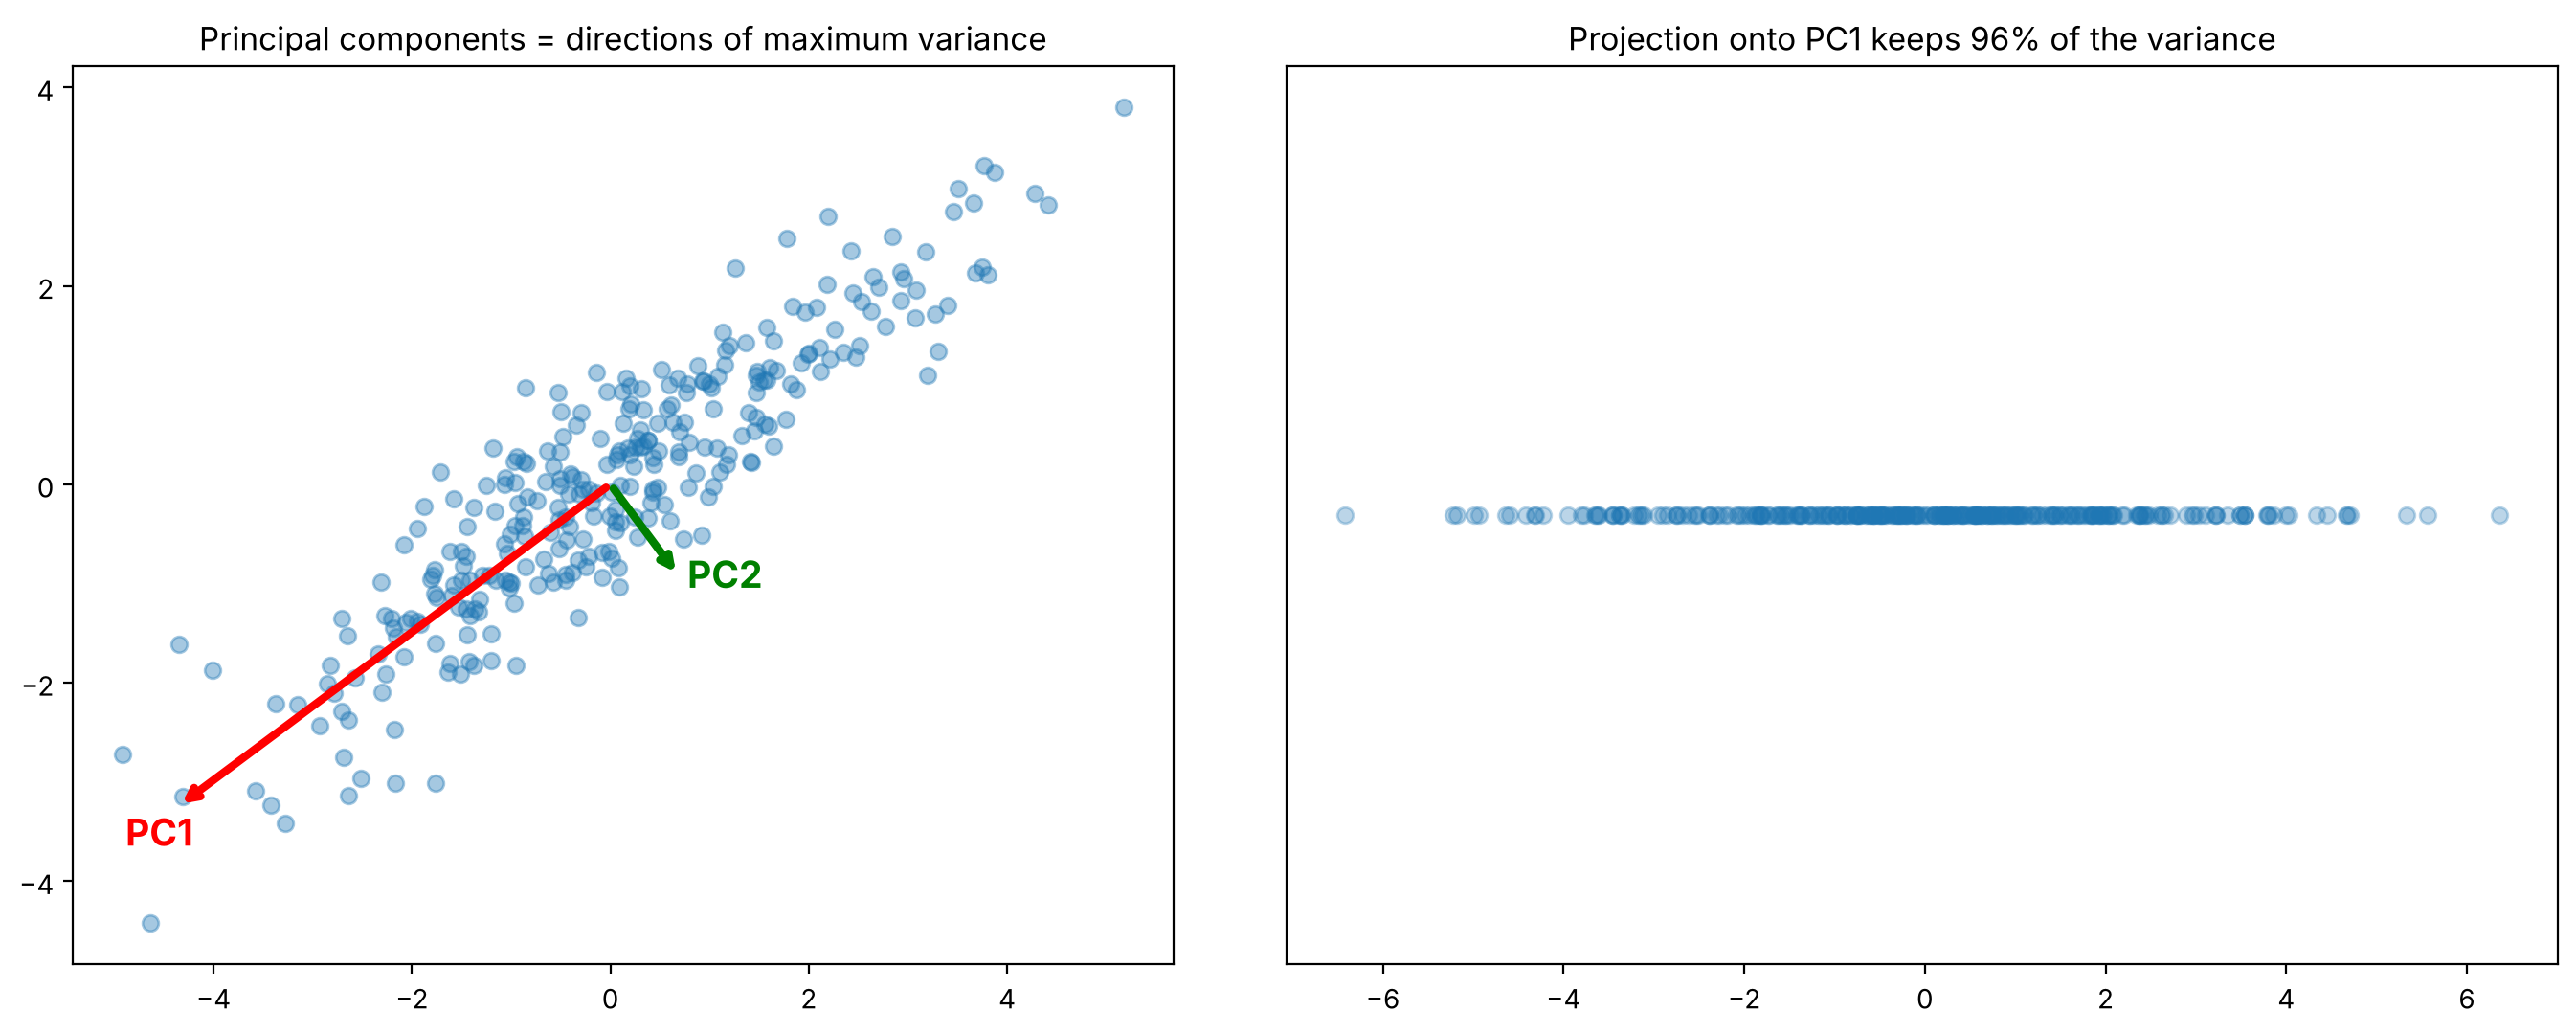

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)
X2 = rng.multivariate_normal([0, 0], [[3, 2.2], [2.2, 2]], size=300)

X_centered = X2 - X2.mean(axis=0)
cov = np.cov(X_centered, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(cov)
order = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(X_centered[:, 0], X_centered[:, 1], alpha=0.4)
for val, vec, color, name in zip(eigenvalues, eigenvectors.T, ["red", "green"], ["PC1", "PC2"]):
    axes[0].annotate("", xy=vec * 2.5 * np.sqrt(val), xytext=(0, 0),
                     arrowprops=dict(arrowstyle="->", color=color, lw=3))
    axes[0].text(*(vec * 2.8 * np.sqrt(val)), name, color=color, fontsize=14, weight="bold")
axes[0].set_aspect("equal")
axes[0].set_title("Principal components = directions of maximum variance")

projected = X_centered @ eigenvectors[:, 0]
axes[1].scatter(projected, np.zeros_like(projected), alpha=0.3)
axes[1].set_yticks([])
axes[1].set_title(f"Projection onto PC1 keeps {eigenvalues[0] / eigenvalues.sum():.0%} of the variance")
plt.tight_layout()
plt.show()

<div dir="rtl">

با تصویر کردن داده‌ی دوبعدی روی فقط **یک** مؤلفه، بیش از ۹۰٪ واریانس حفظ شده است.

### ۲.۲ ریاضیات PCA

1. داده را **مرکزی** کن: میانگین هر ویژگی را از آن کم کن.
2. **ماتریس کوواریانس** را حساب کن:

</div>

$$\Sigma = \frac{1}{m-1} X^\top X$$

<div dir="rtl">

3. **بردارهای ویژه (eigenvectors)** و **مقادیر ویژه (eigenvalues)** ماتریس کوواریانس را پیدا کن. هر بردار ویژه یک مؤلفه‌ی اصلی است و مقدار ویژه‌ی متناظر، واریانس داده در آن جهت.
4. بردارها را بر اساس مقدار ویژه، به ترتیب نزولی، مرتب کن و $k$ تای اول را انتخاب کن ($W_k$).
5. داده را تصویر کن:

</div>

$$Z = X\, W_k$$

<div dir="rtl">

در عمل، کتابخانه‌ها به‌جای تجزیه‌ی ماتریس کوواریانس از **تجزیه‌ی مقادیر منفرد (SVD)** خود داده استفاده می‌کنند که از نظر عددی پایدارتر است. نتیجه یکسان است.

### ۲.۳ پیاده‌سازی از صفر و مقایسه با scikit-learn

</div>

In [2]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = load_wine(as_frame=True)
X_wine = StandardScaler().fit_transform(wine.data)

def pca_from_scratch(X, k):
    X_c = X - X.mean(axis=0)
    vals, vecs = np.linalg.eigh(np.cov(X_c, rowvar=False))
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    return X_c @ vecs[:, :k], vals / vals.sum()

Z_ours, ratio_ours = pca_from_scratch(X_wine, 2)
pca = PCA(n_components=2).fit(X_wine)
Z_sk = pca.transform(X_wine)

print("Explained variance ratio (ours):   ", ratio_ours[:2].round(4))
print("Explained variance ratio (sklearn):", pca.explained_variance_ratio_.round(4))
print("Same projection (up to sign):", np.allclose(np.abs(Z_ours), np.abs(Z_sk)))

Explained variance ratio (ours):    [0.362  0.1921]
Explained variance ratio (sklearn): [0.362  0.1921]
Same projection (up to sign): True


<div dir="rtl">

علامت هر مؤلفه دلخواه است؛ $\mathbf{w}$ و $-\mathbf{w}$ هر دو جهت معتبری‌اند. پس دو پیاده‌سازی ممکن است فقط در علامت تفاوت داشته باشند.

### ۲.۴ چند مؤلفه نگه داریم؟

**نسبت واریانس توضیح‌داده‌شده** نشان می‌دهد هر مؤلفه چه سهمی از کل واریانس را دارد. یک قاعده‌ی رایج: آن‌قدر مؤلفه نگه دارید که مثلاً ۹۵٪ واریانس حفظ شود.

</div>

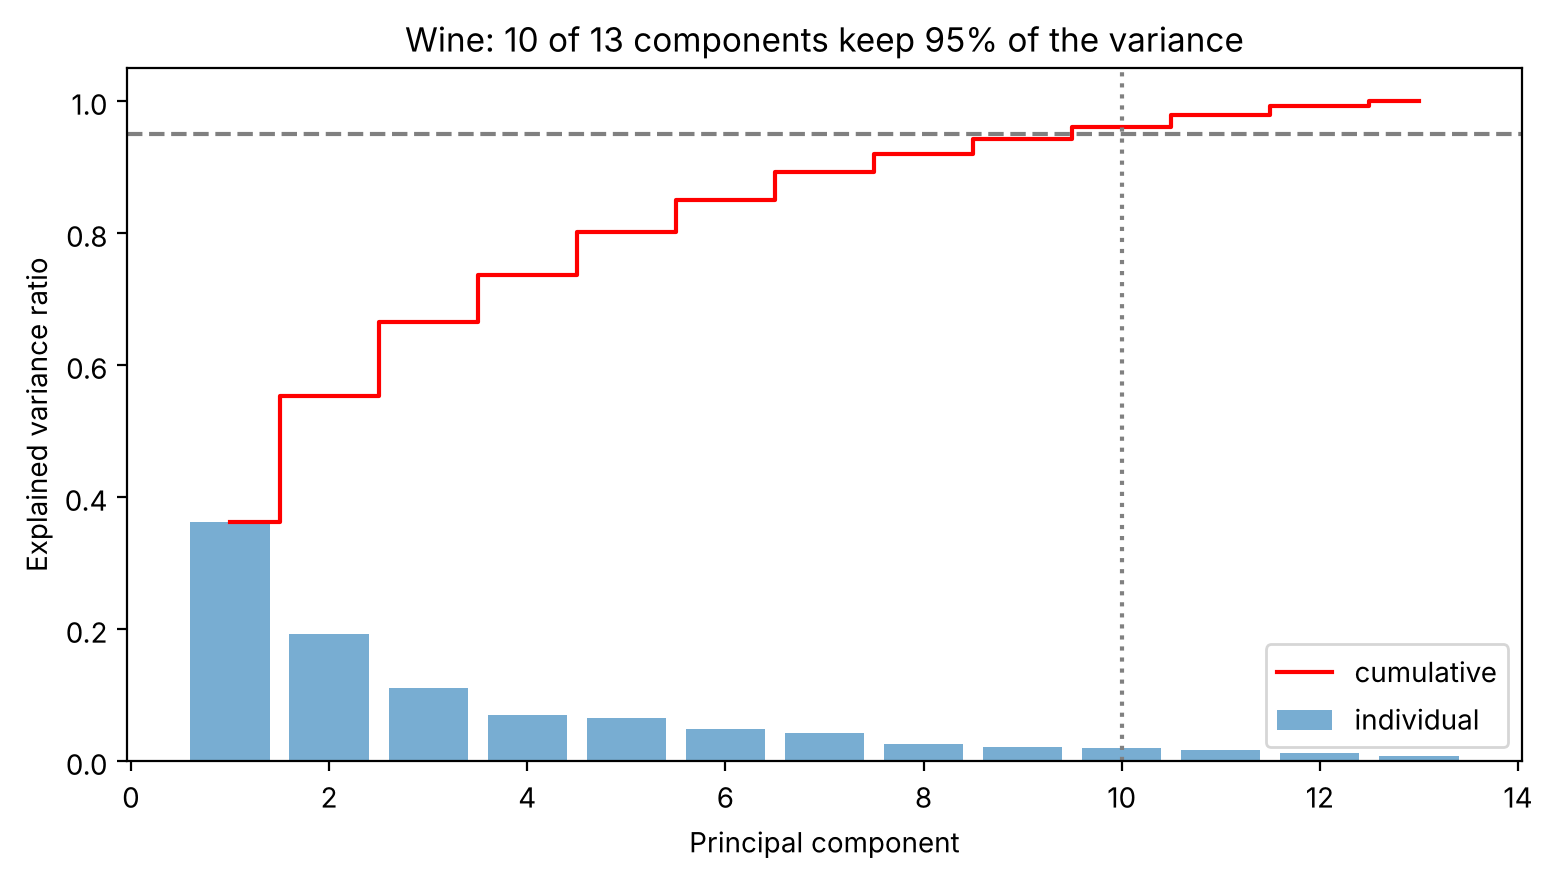

In [3]:
pca_full = PCA().fit(X_wine)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cumulative >= 0.95)) + 1

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(range(1, 14), pca_full.explained_variance_ratio_, alpha=0.6, label="individual")
ax.step(range(1, 14), cumulative, where="mid", color="red", label="cumulative")
ax.axhline(0.95, color="gray", linestyle="--")
ax.axvline(n95, color="gray", linestyle=":")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title(f"Wine: {n95} of 13 components keep 95% of the variance")
ax.legend()
plt.show()

<div dir="rtl">

در scikit-learn می‌توان مستقیم نوشت `PCA(n_components=0.95)` تا تعداد مؤلفه‌ها خودکار انتخاب شود.

### ۲.۵ مصورسازی و تفسیر مؤلفه‌ها

</div>

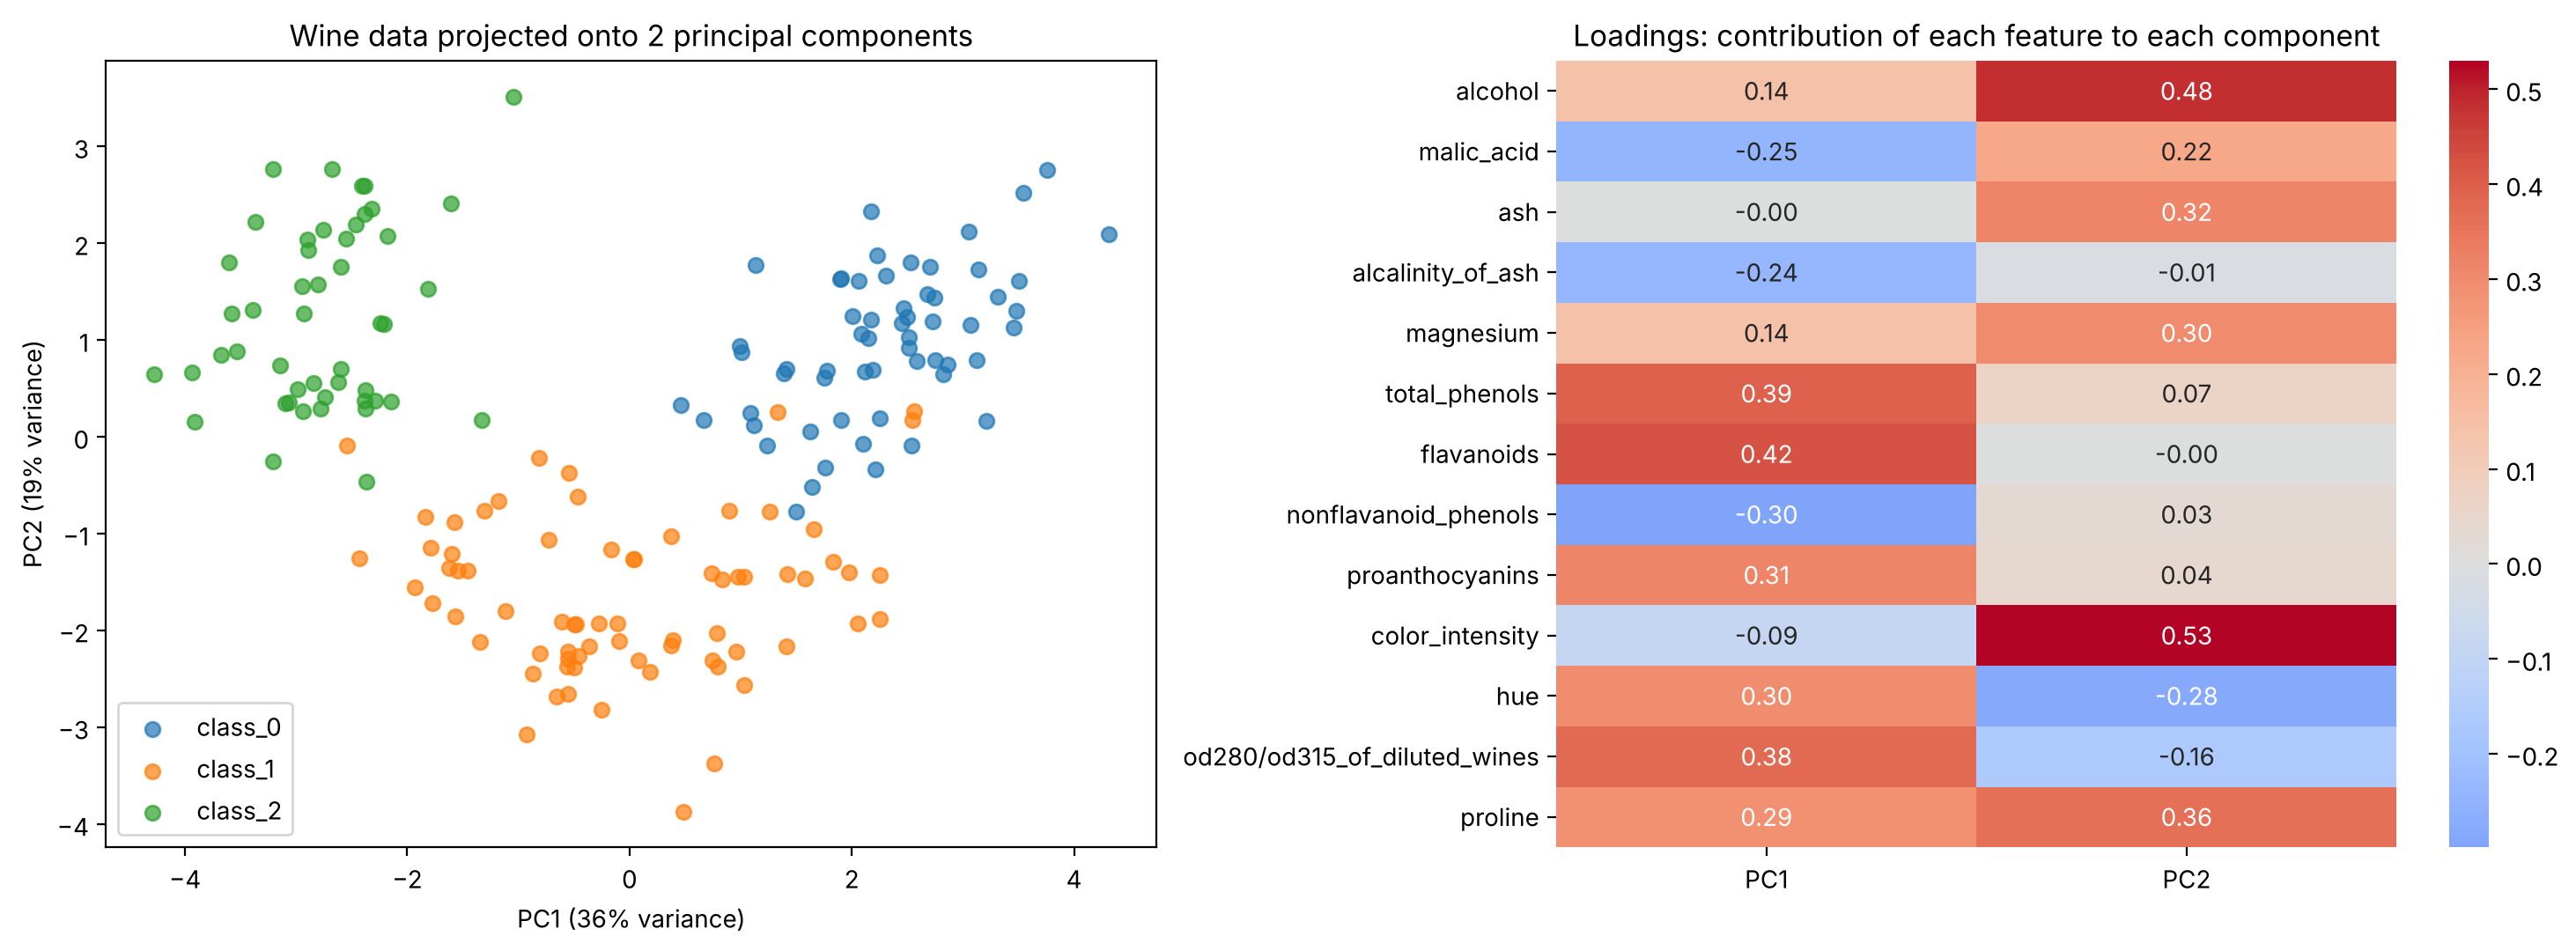

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for cls, name in enumerate(wine.target_names):
    axes[0].scatter(Z_sk[wine.target == cls, 0], Z_sk[wine.target == cls, 1], label=name, alpha=0.7)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
axes[0].set_title("Wine data projected onto 2 principal components")
axes[0].legend()

loadings = pd.DataFrame(pca.components_.T, index=wine.feature_names, columns=["PC1", "PC2"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Loadings: contribution of each feature to each component")
plt.tight_layout()
plt.show()

<div dir="rtl">

با اینکه PCA از برچسب‌ها استفاده نکرده، سه نوع شراب در دو بعد اول تقریباً جدا شده‌اند. **بارها (loadings)** نشان می‌دهند هر مؤلفه ترکیبی از کدام ویژگی‌هاست؛ مثلاً ویژگی‌های مرتبط با فنول‌ها و فلاونوئیدها سهم بزرگی در PC1 دارند.

### ۲.۶ مقیاس‌بندی قبل از PCA ضروری است

PCA دنبال بیشترین **واریانس** است. اگر ویژگی‌ها مقیاس متفاوتی داشته باشند، ویژگی با اعداد بزرگ‌تر (مثل `proline` با مقادیر تا ۱۷۰۰) به‌تنهایی بر مؤلفه‌ی اول غلبه می‌کند:

</div>

In [5]:
raw_pca = PCA(n_components=2).fit(wine.data)
top_feature = wine.feature_names[np.argmax(np.abs(raw_pca.components_[0]))]
print(f"Without scaling: PC1 explains {raw_pca.explained_variance_ratio_[0]:.1%} of the variance "
      f"and is dominated by '{top_feature}' (loading = {raw_pca.components_[0].max():.3f})")
print(f"With scaling:    PC1 explains {pca.explained_variance_ratio_[0]:.1%} of the variance")

Without scaling: PC1 explains 99.8% of the variance and is dominated by 'proline' (loading = 1.000)
With scaling:    PC1 explains 36.2% of the variance


<div dir="rtl">

بدون مقیاس‌بندی، PC1 تقریباً همان ستون `proline` است. نتیجه‌ی ظاهراً عالی ۹۹٪ واریانس، فقط حاصل واحد اندازه‌گیری است.

</div>

<div dir="rtl">

## ۳. PCA روی تصاویر: ارقام دست‌نویس

مجموعه‌داده‌ی `digits` شامل ۱۷۹۷ تصویر ۸×۸ از ارقام ۰ تا ۹ است؛ یعنی هر تصویر ۶۴ ویژگی (پیکسل) دارد.

</div>

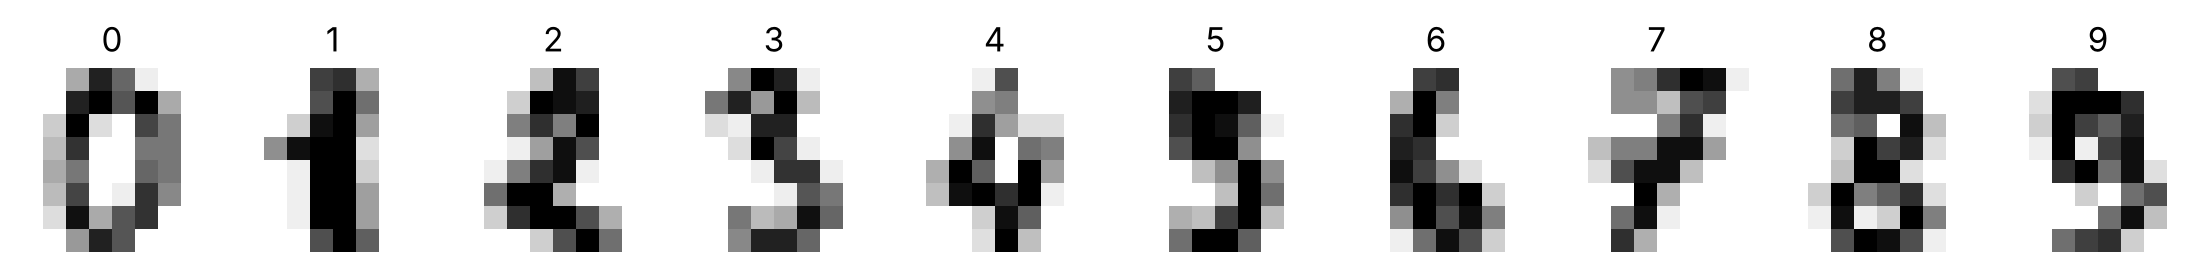

In [6]:
from sklearn.datasets import load_digits

digits = load_digits()
X_digits, y_digits = digits.data, digits.target

fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for ax, img, label in zip(axes, digits.images, digits.target):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.show()

In [7]:
pca_digits = PCA().fit(X_digits)
cum = np.cumsum(pca_digits.explained_variance_ratio_)
print(f"Components for 90% variance: {np.argmax(cum >= 0.90) + 1} of 64")
print(f"Components for 95% variance: {np.argmax(cum >= 0.95) + 1} of 64")

Components for 90% variance: 21 of 64
Components for 95% variance: 29 of 64


<div dir="rtl">

### فشرده‌سازی و بازسازی

می‌توانیم تصویر را با $k$ مؤلفه فشرده کنیم و سپس با `inverse_transform` به فضای ۶۴ بعدی برگردانیم. هرچه $k$ بیشتر، بازسازی دقیق‌تر:

</div>

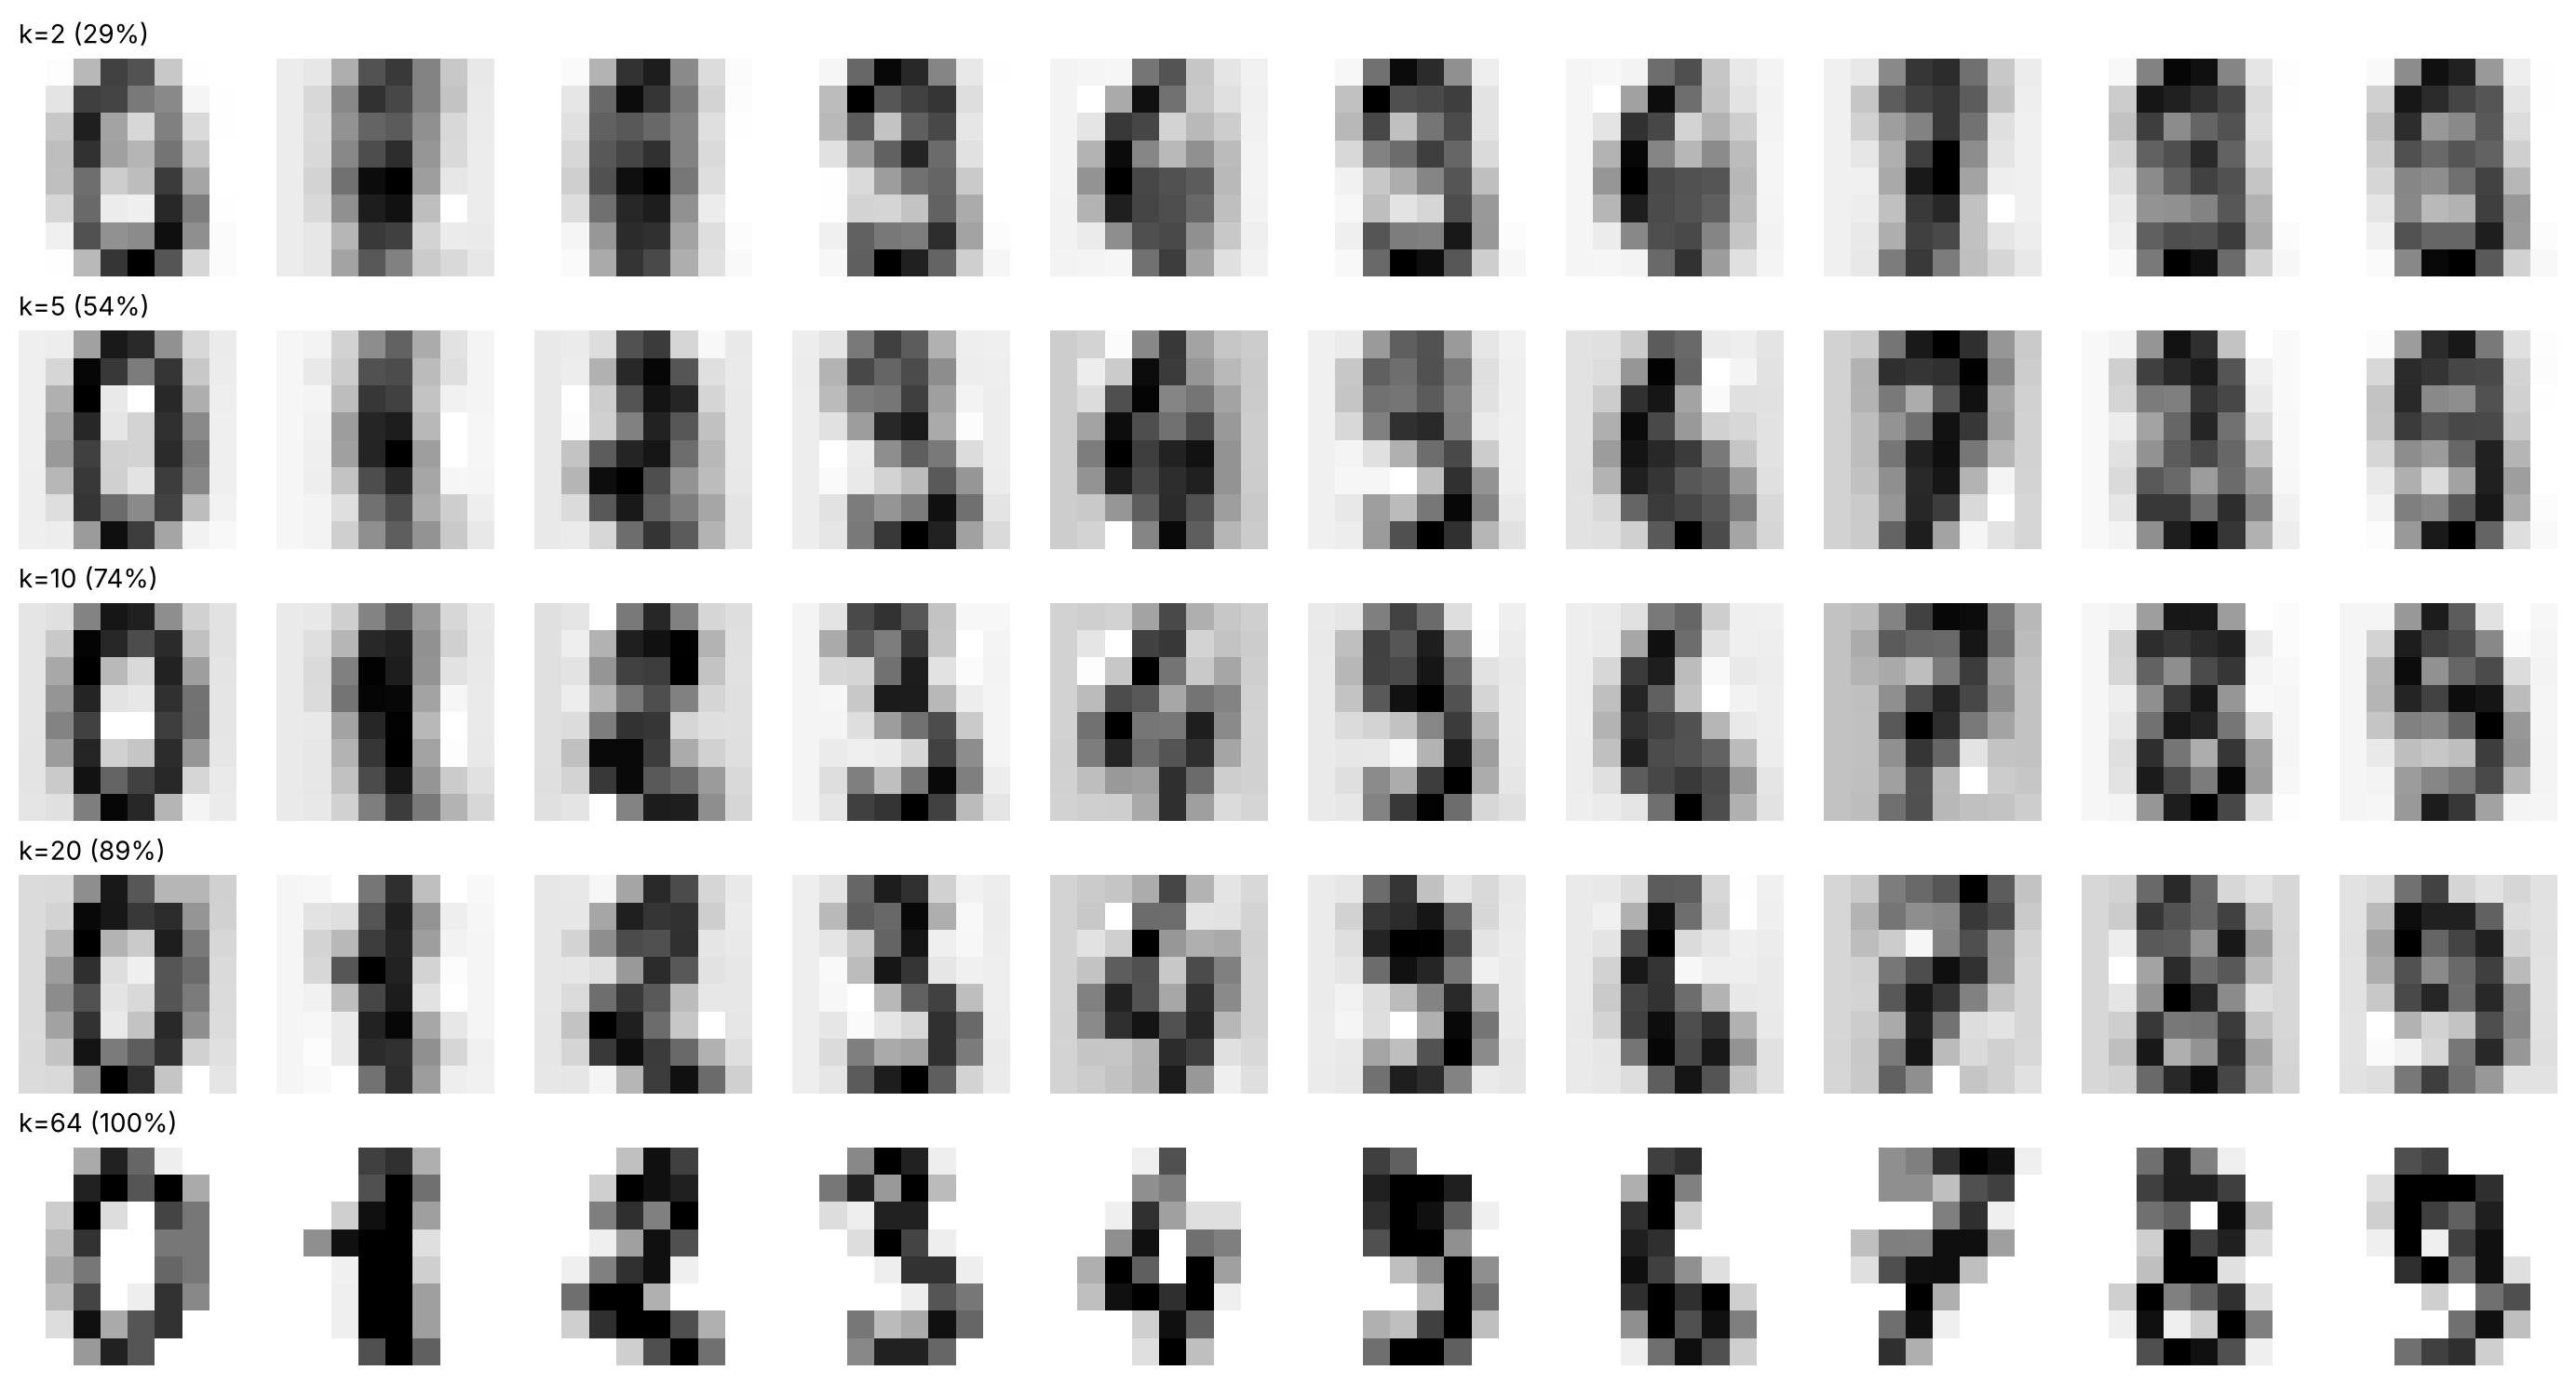

In [8]:
fig, axes = plt.subplots(5, 10, figsize=(14, 7.5))
for row, k in enumerate([2, 5, 10, 20, 64]):
    pca_k = PCA(n_components=k).fit(X_digits)
    reconstructed = pca_k.inverse_transform(pca_k.transform(X_digits[:10]))
    for col in range(10):
        axes[row, col].imshow(reconstructed[col].reshape(8, 8), cmap="gray_r")
        axes[row, col].axis("off")
    axes[row, 0].set_title(f"k={k} ({pca_k.explained_variance_ratio_.sum():.0%})", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

<div dir="rtl">

با فقط ۱۰ تا ۲۰ عدد به‌جای ۶۴، ارقام کاملاً قابل تشخیص‌اند.

### PCA به‌عنوان پیش‌پردازش

کاهش ابعاد با PCA قبل از مدل می‌تواند آموزش را سریع‌تر کند و گاهی با حذف نویز، دقت را هم بهتر کند. تعداد مؤلفه‌ها یک ابرپارامتر است و باید با اعتبارسنجی انتخاب شود:

</div>

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split

Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_digits, y_digits, test_size=0.25,
                                                        stratify=y_digits, random_state=42)
pipe = Pipeline([("scale", StandardScaler()), ("pca", PCA()), ("clf", LogisticRegression(max_iter=2000))])
search = GridSearchCV(pipe, {"pca__n_components": [5, 10, 20, 30, 40, 64]}, cv=5, n_jobs=-1)
search.fit(Xd_train, yd_train)

pd.DataFrame(search.cv_results_)[["param_pca__n_components", "mean_test_score", "mean_fit_time"]].round(3)

,param_pca__n_components,mean_test_score,mean_fit_time
0,5,0.823,0.029
1,10,0.883,0.021
2,20,0.950,0.016
3,30,0.962,0.018
4,40,0.966,0.015
5,64,0.970,0.017


<div dir="rtl">

در این داده، بهترین دقت با همه‌ی ۶۴ ویژگی به دست می‌آید؛ ولی با ۳۰ مؤلفه، یعنی کمتر از نصف ابعاد، دقت تقریباً یکسان است. PCA همیشه دقت را بالا نمی‌برد؛ ارزش اصلی آن در داده‌های بسیار پرابعاد، کاهش هزینه‌ی محاسبه و حافظه است.

## ۴. تحلیل تفکیک خطی (LDA)

PCA **بدون نظارت** است و فقط به واریانس اهمیت می‌دهد، نه به برچسب‌ها. ولی جهت با بیشترین واریانس، لزوماً بهترین جهت برای **جدا کردن کلاس‌ها** نیست.

**LDA (Linear Discriminant Analysis)** روشی **نظارت‌شده** است: جهتی را پیدا می‌کند که فاصله‌ی **بین** میانگین کلاس‌ها را بیشینه و پراکندگی **درون** هر کلاس را کمینه کند. LDA حداکثر $C-1$ مؤلفه تولید می‌کند ($C$ تعداد کلاس‌ها).

</div>

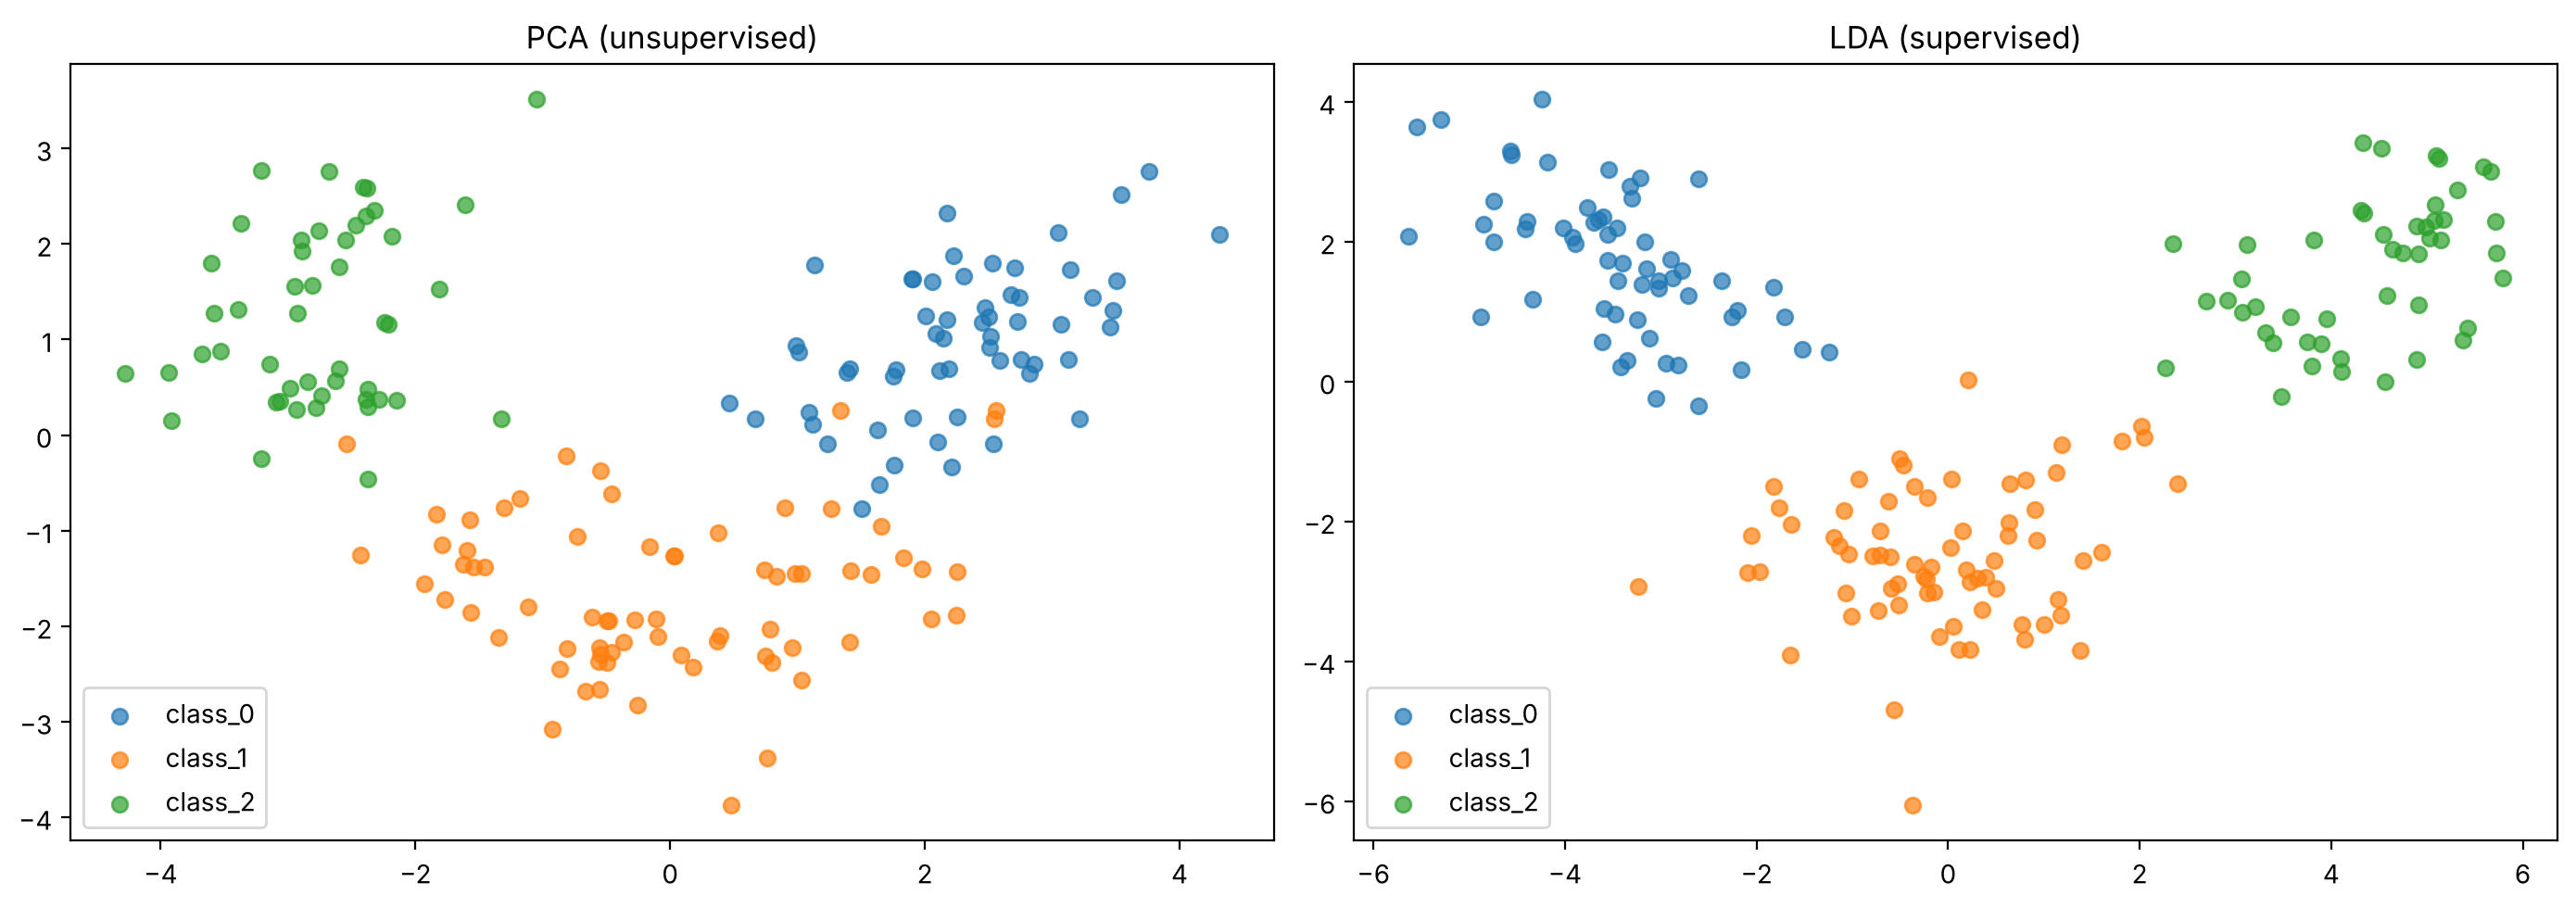

In [10]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

Z_lda = LinearDiscriminantAnalysis(n_components=2).fit_transform(X_wine, wine.target)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, Z, title in [(axes[0], Z_sk, "PCA (unsupervised)"), (axes[1], Z_lda, "LDA (supervised)")]:
    for cls, name in enumerate(wine.target_names):
        ax.scatter(Z[wine.target == cls, 0], Z[wine.target == cls, 1], label=name, alpha=0.7)
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

<div dir="rtl">

LDA کلاس‌ها را بسیار بهتر از هم جدا کرده، چون از برچسب‌ها استفاده می‌کند. ولی دقت کنید: چون LDA برچسب را می‌بیند، باید **فقط روی داده‌ی آموزش** `fit` شود (داخل Pipeline)، وگرنه نشت داده رخ می‌دهد.

## ۵. Kernel PCA: ساختارهای غیرخطی

PCA فقط تصویرهای **خطی** پیدا می‌کند. برای داده‌هایی مثل دو دایره‌ی تودرتو، هیچ تصویر خطی‌ای کلاس‌ها را جدا نمی‌کند. **Kernel PCA** با همان ترفند کرنل جلسه‌ی ۷، PCA را در یک فضای ضمنی پرابعاد اجرا می‌کند:

</div>

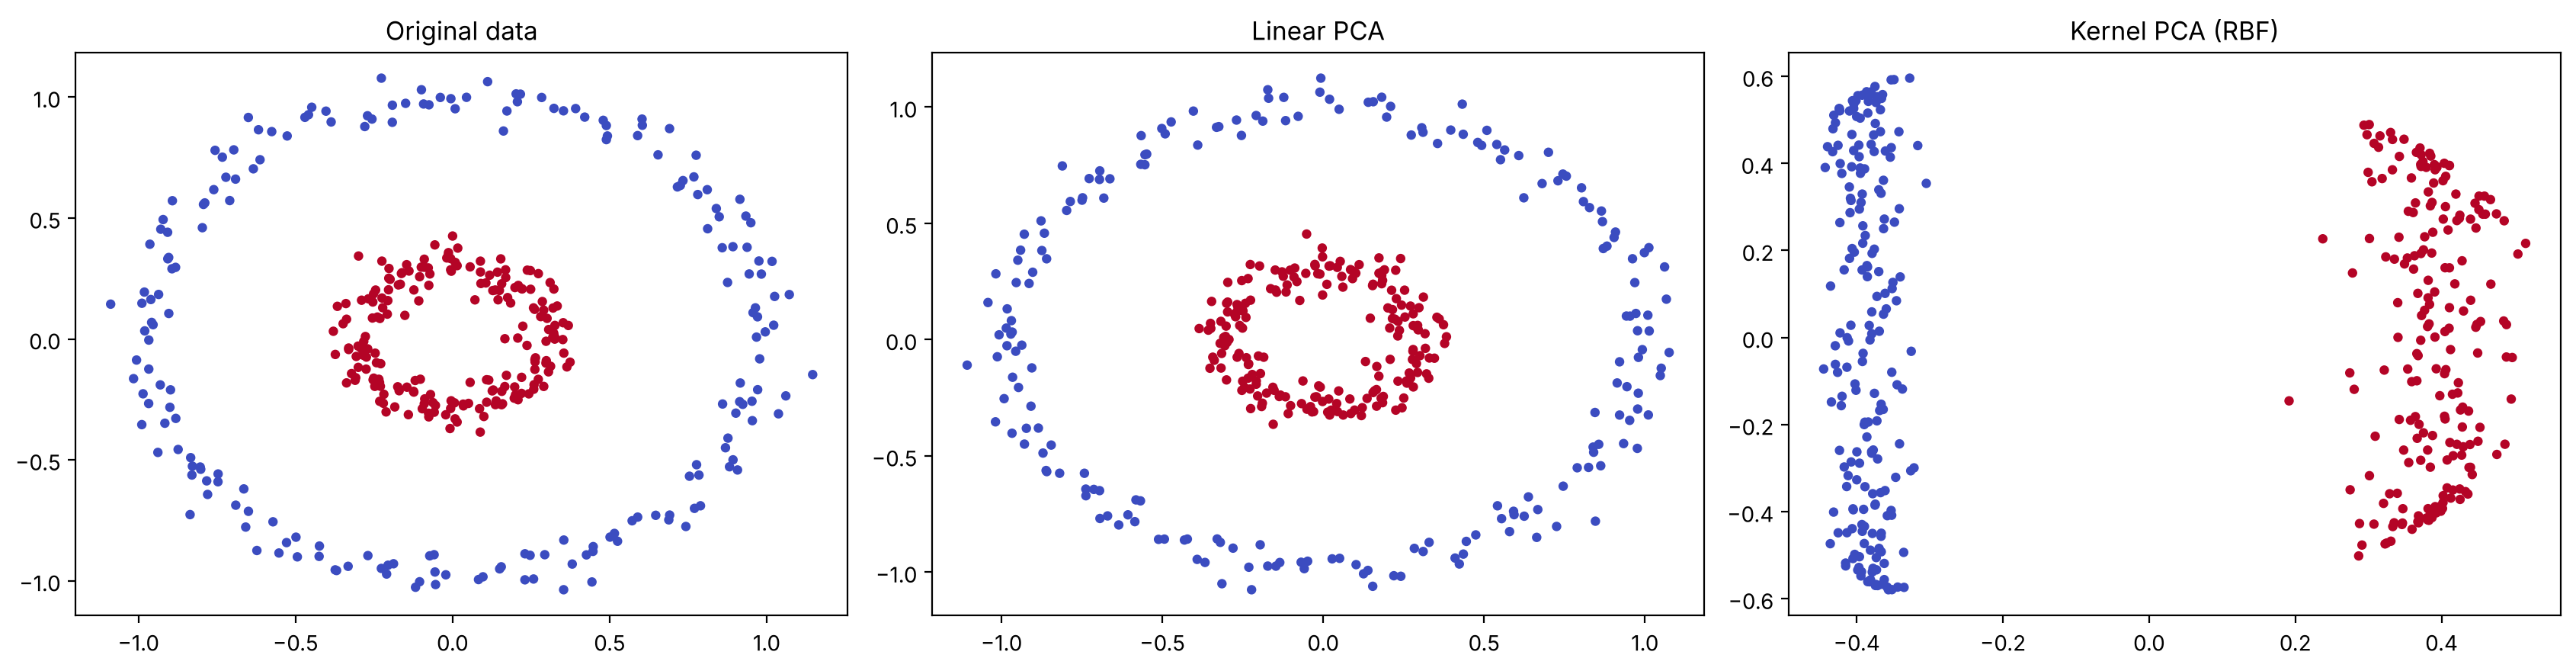

In [11]:
from sklearn.datasets import make_circles
from sklearn.decomposition import KernelPCA

X_circ, y_circ = make_circles(n_samples=400, factor=0.3, noise=0.05, random_state=42)
Z_lin = PCA(n_components=2).fit_transform(X_circ)
Z_kpca = KernelPCA(n_components=2, kernel="rbf", gamma=2).fit_transform(X_circ)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, Z, title in [(axes[0], X_circ, "Original data"), (axes[1], Z_lin, "Linear PCA"),
                     (axes[2], Z_kpca, "Kernel PCA (RBF)")]:
    ax.scatter(Z[:, 0], Z[:, 1], c=y_circ, cmap="coolwarm", s=12)
    ax.set_title(title)
plt.tight_layout()
plt.show()

<div dir="rtl">

PCA خطی فقط داده را می‌چرخاند، ولی Kernel PCA دو دایره را طوری تصویر می‌کند که با یک خط ساده جدا می‌شوند؛ حتی فقط مؤلفه‌ی اول برای جدا کردن کافی است. مثل SVM، نتیجه به `gamma` حساس است: با `gamma` خیلی کوچک یا خیلی بزرگ این جداسازی از بین می‌رود.

## ۶. t-SNE: مصورسازی داده‌های پرابعاد

**t-SNE** (t-distributed Stochastic Neighbor Embedding) یک روش **غیرخطی** است که مخصوص **مصورسازی** طراحی شده. ایده: نقاطی که در فضای اصلی همسایه‌اند، در فضای دوبعدی هم همسایه بمانند. t-SNE ساختار **محلی** را بسیار خوب حفظ می‌کند.

</div>

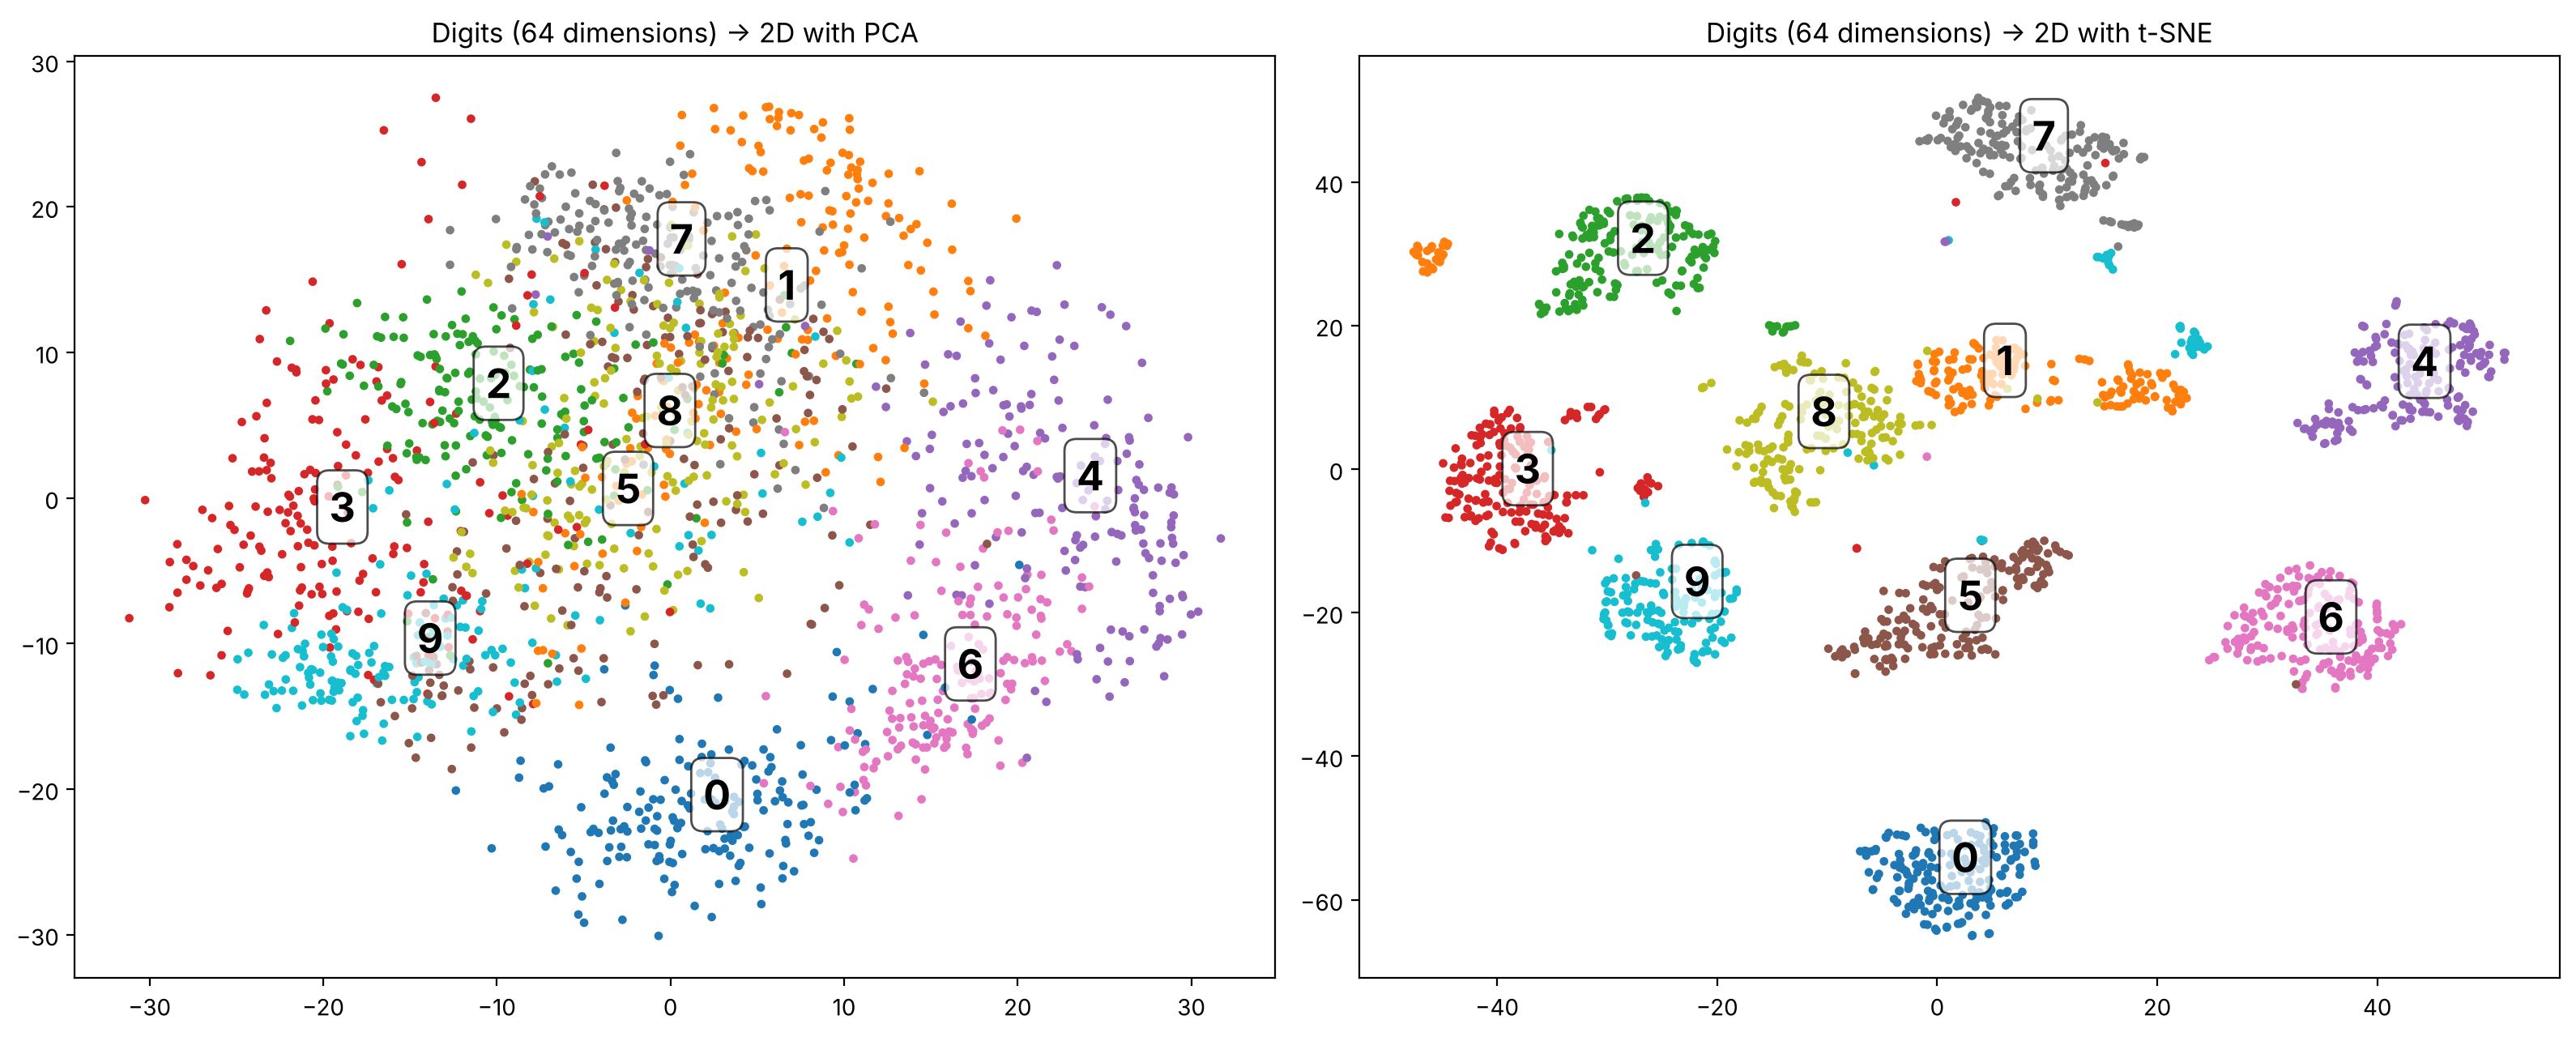

In [12]:
from sklearn.manifold import TSNE

Z_pca_digits = PCA(n_components=2).fit_transform(X_digits)
Z_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_digits)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, Z, title in [(axes[0], Z_pca_digits, "PCA"), (axes[1], Z_tsne, "t-SNE")]:
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=y_digits, cmap="tab10", s=8)
    for d in range(10):
        cx, cy = np.median(Z[y_digits == d], axis=0)
        ax.text(cx, cy, str(d), fontsize=18, weight="bold",
                bbox=dict(facecolor="white", alpha=0.7, boxstyle="round"))
    ax.set_title(f"Digits (64 dimensions) → 2D with {title}")
plt.tight_layout()
plt.show()

<div dir="rtl">

PCA در دو بعد فقط بخشی از ساختار را نشان می‌دهد و بسیاری از ارقام روی هم افتاده‌اند. t-SNE، بدون دیدن برچسب‌ها، ده رقم را در ده خوشه‌ی کاملاً مجزا قرار داده است.

**هشدارهای مهم درباره‌ی t-SNE:**
- **فقط برای مصورسازی** است. `transform` برای داده‌ی جدید ندارد، پس به‌عنوان پیش‌پردازش مدل استفاده نمی‌شود.
- **اندازه‌ی خوشه‌ها و فاصله‌ی بین خوشه‌ها معنادار نیست.** فقط همسایگی‌های محلی قابل تفسیرند.
- نتیجه به ابرپارامتر `perplexity` (تقریباً تعداد همسایه‌های مؤثر، معمولاً ۵ تا ۵۰) و مقدار اولیه‌ی تصادفی حساس است.
- برای داده‌ی بزرگ کند است؛ معمولاً اول با PCA به حدود ۵۰ بعد می‌رسانند و بعد t-SNE اجرا می‌کنند.

**UMAP** (از کتابخانه‌ی `umap-learn`) جایگزین مدرن و سریع‌تر t-SNE است که ساختار کلی را هم بهتر حفظ می‌کند و `transform` هم دارد.

## ۷. جمع‌بندی

| روش | نوع | نظارت | کاربرد اصلی |
|---|---|---|---|
| PCA | خطی | بدون نظارت | فشرده‌سازی، پیش‌پردازش، مصورسازی سریع |
| LDA | خطی | نظارت‌شده | کاهش ابعاد برای طبقه‌بندی |
| Kernel PCA | غیرخطی | بدون نظارت | ساختارهای غیرخطی |
| t-SNE / UMAP | غیرخطی | بدون نظارت | **مصورسازی** داده‌ی پرابعاد |

- PCA جهت‌های با بیشترین واریانس را پیدا می‌کند و قبل از آن **مقیاس‌بندی** ضروری است.
- تعداد مؤلفه‌ها را با واریانس توضیح‌داده‌شده یا اعتبارسنجی انتخاب کنید.
- t-SNE برای دیدن داده عالی است، ولی فاصله‌های کلی آن را تفسیر نکنید.

## ۸. تمرین

1. PCA را روی داده‌ی سرطان سینه (۳۰ ویژگی) اجرا کنید. چند مؤلفه ۹۵٪ واریانس را حفظ می‌کند؟ داده را در دو بعد اول رسم کنید.
2. در Pipeline ارقام، `LogisticRegression` را با `KNeighborsClassifier` عوض کنید. PCA برای k-NN مفیدتر است یا برای رگرسیون لجستیک؟ چرا؟
3. t-SNE را با `perplexity` برابر ۵، ۳۰ و ۱۰۰ روی ارقام اجرا کنید و نتایج را مقایسه کنید.
4. تصاویر ارقام را با ۱۰ مؤلفه‌ی PCA فشرده کنید و نسبت فشرده‌سازی و خطای بازسازی (MSE) را حساب کنید.

</div>